Successfully fetched road network for Buckhannon, West Virginia, USA.
Source Node: 156138260
Target Node: 2643114653
Path found from Source Node 156138260 to Target Node 2643114653.
Length (miles): 0.9980411747406279
Energy consumed (kWh): 0.6179968228638502


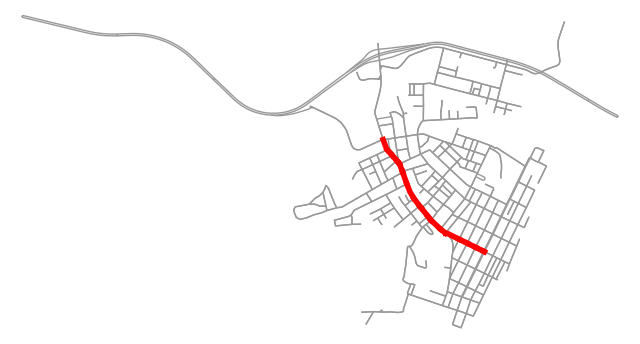

In [ ]:
import osmnx as ox
import networkx as nx
import requests
import numpy as np
import cvxpy as cp
import matplotlib.pyplot as plt
from shapely.geometry import LineString

# get elevation using Open-Meteo API
def get_elevation(lat, lon):
    url = f"https://api.open-meteo.com/v1/elevation?latitude={lat}&longitude={lon}"
    response = requests.get(url)
    
    if response.status_code == 200:
        elevation = response.json().get("elevation", [None])[0]
        return elevation if elevation is not None else 0
    else:
        print(f"Error: {response.status_code}, {response.text}")
        return 0

def get_road_network():
    while True:
        place_state = input("State in the USA: ")
        place_city = input("City in given state: ")
        place_name = f"{place_city}, {place_state}, USA"
        
        try:
            # attempt to get road network
            graph = ox.graph_from_place(place_name, network_type="drive")

            # check if graph empty
            if graph.number_of_nodes() == 0:
                raise ValueError(f"No data found for {place_name}. Please try again.")
            
            print(f"Successfully fetched road network for {place_name}.")
            return graph

        except ValueError as e:
            print(f"Error: {e}")
        except Exception as e:
            print(f"Unexpected error: {e}")
            break

# get road network
graph = get_road_network()

# copy of graph
G = graph.copy()

# get elevation for nodes
for node, data in graph.nodes(data=True):
    lat, lon = data['y'], data['x']
    data['elevation'] = get_elevation(lat, lon)

# calculate road grade for each edge
def calculate_edge_grades(graph):
    for u, v, k, data in graph.edges(keys=True, data=True):
        elevation_u = graph.nodes[u].get('elevation', 0)
        elevation_v = graph.nodes[v].get('elevation', 0)
        length = data.get('length', 1)
        
        grade = ((elevation_v - elevation_u) / length) * 100
        data['grade'] = grade

calculate_edge_grades(graph)

# energy cost based on road grade
def calculate_energy_from_grade(grade):
    if grade < -9:        return -0.332
    elif -9 <= grade < -7: return -0.217
    elif -7 <= grade < -5: return -0.148
    elif -5 <= grade < -3: return -0.121
    elif -3 <= grade < -1: return -0.073
    elif -1 <= grade <= 1: return 0
    elif 1 < grade <= 3:   return 0.085
    elif 3 < grade <= 5:   return 0.152
    elif 5 < grade <= 7:   return 0.203
    elif 7 < grade <= 9:   return 0.306
    elif 9 < grade <= 11:  return 0.358
    else:                  return 0.552

for u, v, k, data in graph.edges(keys=True, data=True):
    grade = data.get('grade', 0)
    base_length = data.get('length', 1)
    energy_factor = calculate_energy_from_grade(grade)
    
    # calculate energy cost as function of length and grade 
    data['energy_cost'] = base_length * (0.38182 + energy_factor)
    data['weighted_cost'] = base_length  # default to distance for multi-objective

# source and target nodes
def get_coordinates(graph, label):
    while True:
        try:
            lat = float(input(f"Enter {label} latitude: "))
            lon = float(input(f"Enter {label} longitude: "))

            # Find the nearest node to the provided coordinates
            node = ox.nearest_nodes(graph, X=lon, Y=lat)
            print(f"{label} Node: {node}")
            return node

        except ValueError:
            print("Invalid latitude or longitude. Please enter valid numbers.")
        except Exception as e:
            print(f"Error finding nearest node: {e}. Try again.")

source_node = get_coordinates(graph, "Source")
target_node = get_coordinates(graph, "Target")

if not nx.has_path(G, source_node, target_node):
    print("No path exists between source and target. Exiting.")
    exit()
else:
    print(f"Path found from Source Node {source_node} to Target Node {target_node}.")


# optimizing based on energy consumption and distance
edges = list(graph.edges(keys=True))
nodes = list(graph.nodes)
num_edges = len(edges)
num_nodes = len(nodes)

# weighting energy consumption 0.5, weighting distance 0.5
alpha = 0.5

# combining weighted energy cost and weighted distance cost
edge_weights = np.array([
    alpha * graph[u][v][k].get('energy_cost', 1) + 
    (1 - alpha) * graph[u][v][k].get('length', 1)
    for u, v, k in edges
])

# flow conservation
incidence_matrix = np.zeros((num_nodes, num_edges))
node_idx = {node: idx for idx, node in enumerate(nodes)}

for edge_idx, (u, v, k) in enumerate(edges):
    incidence_matrix[node_idx[u], edge_idx] = 1
    incidence_matrix[node_idx[v], edge_idx] = -1

x = cp.Variable(num_edges, boolean=True)

# objective function; minimize based on energy consumption and distance
objective = cp.Minimize(edge_weights @ x)

b = np.zeros(num_nodes)
b[node_idx[source_node]] = 1
b[node_idx[target_node]] = -1

constraints = [incidence_matrix @ x == b]

problem = cp.Problem(objective, constraints)
problem.solve(solver=cp.GLPK_MI)

# visualization
if problem.status in ["infeasible", "unbounded"]:
    print("No feasible path found.")
else:
    shortest_path_edges = [edges[i] for i in range(num_edges) if x.value[i] > 0.5]

    path_nodes = [shortest_path_edges[0][0]]
    for u, v, k in shortest_path_edges:
        path_nodes.append(v)

    path_length_meters = sum(graph[u][v][k]['length'] for u, v, k in shortest_path_edges)
    path_length_miles = path_length_meters / 1609.34
    energy_consumed = sum(graph[u][v][k]['energy_cost'] for u, v, k in shortest_path_edges) / 1000

    print(f"Length (miles): {path_length_miles}")
    print(f"Energy consumed (kWh): {energy_consumed}")

    fig, ax = ox.plot_graph(graph, node_size=0, bgcolor='white', show=False, close=False)

    for u, v, k in shortest_path_edges:
        if G.has_edge(u, v, k):
            edge = G[u][v][k]
            if 'geometry' in edge:
                line = edge['geometry']
            else:
                line = LineString([(G.nodes[u]['x'], G.nodes[u]['y']),
                                   (G.nodes[v]['x'], G.nodes[v]['y'])])
            ax.plot(*line.xy, linewidth=4, color='red')
    plt.show()
